# 00-MAIN-Pipeline v2: Building Age Classification (Madrid -> Amsterdam)
**Final method v2 (Wed 18 Nov, 00:30):** temporal haze cleaning -> 132 time-series features -> **+ neighbourhood features** (average features of the surrounding pixels in a 3x3 and a 7x7 window, satellite features only) -> Random Forest on Madrid -> Amsterdam own scaling -> blend3 transfer -> **5x5 smoothing**.

Both additions passed a rule fixed in advance on the 80% training split and were confirmed on hidden neighbourhoods (notebooks 08 and 09, PROJECT_LOG sections 7i). The previous version (v1) is kept in `submission_frozen_v1/` and in `00-MAIN-Pipeline-FINAL.ipynb`.

**Run:** Kernel > Restart Kernel and Run All (about 1.5 hours; the models are 3x wider than v1).
**Writes:** `models/` (overwrites v1's models: the v1 copy is safe in `submission_frozen_v1/`), `results/` (v2 files have `_v2` in their name), `results_table_v2.csv`, `f1_vs_log2n_v2.png`.

In [1]:
# ===== SETTINGS ONLY =====
SEED = 42
SHOTS = [5, 25, 50, 100, 200]
N_TRIALS = 10
METHOD = "blend3"
EVENTS = {"Madrid": 1960, "Amsterdam": 1945}
SKIP_CLEAN = True        # clean/ and features files from v1 are identical in v2 (rebuilt if missing)
SKIP_FEATURES = True
RUN_MADRID_CV = True     # 5x5 random CV + 5-fold spatial CV on Madrid
SPATIAL_BLOCK = 50       # 1.5 km blocks for spatial CV

In [2]:
%load_ext autoreload
%autoreload 2
import os, json, random, time
from pathlib import Path
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, confusion_matrix
import data_prep as dp, features_v3 as fv3, transfer_v3 as tv3, predict
assert hasattr(dp, "TEMPORAL_FACTOR"), "old data_prep.py: needs the temporal haze rule"
assert tv3.NEIGHBOUR_RADII == (1, 3) and tv3.SMOOTH_RADIUS == 2, "old transfer_v3.py: upload the v2 version"
assert SEED == tv3.SEED
if not Path("submission_frozen_v1").exists(): print("note: no v1 snapshot in this folder (fine for a fresh run)")
random.seed(SEED); np.random.seed(SEED)
os.makedirs("clean", exist_ok=True); os.makedirs("models", exist_ok=True)
RES = Path("results"); RES.mkdir(exist_ok=True)
CITIES = list(EVENTS)
RAW = {"Madrid": "data/madrid_train.parquet", "Amsterdam": "data/amsterdam_data.parquet"}
CLEAN = lambda c: f"clean/clean_{c.lower()}.parquet"
FEATS = lambda c: f"features_{c.lower()}_v3.parquet"
print("scaling:", tv3.SCALING, "| neighbourhood radii:", tv3.NEIGHBOUR_RADII, "| smoothing radius:", tv3.SMOOTH_RADIUS)

scaling: own | neighbourhood radii: (1, 3) | smoothing radius: 2


## Step 1 - Clean + Step 2 - Own features (unchanged from v1)

In [3]:
for city in CITIES:
    if not (SKIP_CLEAN and os.path.exists(CLEAN(city))):
        raw = dp.load_city(RAW[city])
        dp.add_age_class(dp.clean_long_table(raw), EVENTS[city]).to_parquet(CLEAN(city)); del raw
        print("cleaned", city)
    if not (SKIP_FEATURES and os.path.exists(FEATS(city)) and os.path.exists("feature_cols_v3.json")):
        feat, cols = fv3.build_features(pd.read_parquet(CLEAN(city)))
        feat.to_parquet(FEATS(city)); json.dump(list(cols), open("feature_cols_v3.json", "w")); del feat
        print("features", city)
m = pd.read_parquet(FEATS("Madrid")); a = pd.read_parquet(FEATS("Amsterdam"))
own = json.load(open("feature_cols_v3.json"))
print("Madrid pixels:", len(m), "| Amsterdam pixels:", len(a), "| own features:", len(own))
assert m[own].isna().sum().sum() == 0 and a[own].isna().sum().sum() == 0
if (len(m), len(a)) != (76263, 25992): print("WARNING: pixel counts differ from v1")
del m, a

Madrid pixels: 76263 | Amsterdam pixels: 25992 | own features: 132


## Step 3 - Madrid Stage 1 (with neighbourhood features)

In [4]:
t0 = time.time()
data = tv3.load_data(".")
print(f"model inputs per pixel: {len(data['cols'])} (132 own + 2 x 133 neighbourhood)")
assert len(data["cols"]) == 398 and data["Xm"].shape[1] == 398 and data["Xa"].shape[1] == 398
stage1 = tv3.train_stage1(data)
joblib.dump({"rf": stage1["rf"], "scaler_amsterdam": stage1["scaler_a"], "feature_cols": data["cols"],
             "own_feature_cols": data["own_cols"], "neighbour_radii": data["radii"],
             "smooth_alpha": tv3.SMOOTH_ALPHA, "smooth_radius": tv3.SMOOTH_RADIUS,
             "rf_params": tv3.RF_PARAMS, "scaling": tv3.SCALING, "version": "v2"},
            "models/stage1_madrid_model.joblib")
print(f"Stage 1 trained on {len(data['ym']):,} Madrid pixels and saved ({time.time()-t0:.0f}s)")

model inputs per pixel: 398 (132 own + 2 x 133 neighbourhood)
Stage 1 trained on 76,263 Madrid pixels and saved (47s)


In [5]:
# Madrid CV. RANDOM CV (5 folds x 5 repeats, the brief's protocol) is OPTIMISTIC with neighbourhood features:
# a test pixel's neighbours are training pixels. SPATIAL CV (whole 1.5 km blocks held out) is the honest number.
# Both are reported, plus confusion matrix proportions from the spatial CV.
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
madrid_cv = madrid_spatial = None
if RUN_MADRID_CV:
    t0 = time.time()
    f1s = []
    for i, (tr, te) in enumerate(RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED).split(data["Xm"], data["ym"]), 1):
        rf = RandomForestClassifier(**tv3.RF_PARAMS).fit(data["Xm"][tr], data["ym"][tr])
        f1s.append(f1_score(data["ym"][te], rf.predict(data["Xm"][te]), average="macro"))
    madrid_cv = (float(np.mean(f1s)), float(np.std(f1s)))
    print(f"Madrid RANDOM 5x5 CV: {madrid_cv[0]:.4f} +/- {madrid_cv[1]:.4f}  ({time.time()-t0:.0f}s)")

    ids_m = data["ids_m"]
    groups = (ids_m[:, 0] // SPATIAL_BLOCK) * 1_000_000 + ids_m[:, 1] // SPATIAL_BLOCK
    P_oof = np.zeros((len(data["ym"]), 4)); f1s = []
    for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(data["Xm"], data["ym"], groups):
        rf = RandomForestClassifier(**tv3.RF_PARAMS).fit(data["Xm"][tr], data["ym"][tr])
        P_oof[te] = rf.predict_proba(data["Xm"][te])
        f1s.append(f1_score(data["ym"][te], tv3.CLASSES[P_oof[te].argmax(1)], average="macro"))
    madrid_spatial = (float(np.mean(f1s)), float(np.std(f1s)))
    P_s = tv3.smooth_proba(P_oof, ids_m)
    madrid_spatial_smoothed = f1_score(data["ym"], tv3.CLASSES[P_s.argmax(1)], average="macro")
    print(f"Madrid SPATIAL CV: {madrid_spatial[0]:.4f} +/- {madrid_spatial[1]:.4f} | with 5x5 smoothing {madrid_spatial_smoothed:.4f}")
    cm = confusion_matrix(data["ym"], tv3.CLASSES[P_s.argmax(1)], labels=[1, 2, 3, 4]).astype(float)
    cm_prop = pd.DataFrame((cm / cm.sum(1, keepdims=True)).round(3),
                           index=[f"true {c}" for c in range(1, 5)], columns=[f"pred {c}" for c in range(1, 5)])
    display(cm_prop)
    cm_prop.to_csv(RES / "madrid_confusion_proportions_v2_spatial.csv")
    pd.DataFrame([{"random_cv": madrid_cv[0], "random_std": madrid_cv[1], "spatial_cv": madrid_spatial[0],
                   "spatial_std": madrid_spatial[1], "spatial_smoothed": madrid_spatial_smoothed}]).round(4).to_csv(RES / "madrid_cv_v2.csv", index=False)
    print(f"({time.time()-t0:.0f}s)")

Madrid RANDOM 5x5 CV: 0.7328 +/- 0.0032  (696s)
Madrid SPATIAL CV: 0.6290 +/- 0.0337 | with 5x5 smoothing 0.6300


,pred 1,pred 2,pred 3,pred 4
true 1,0.532,0.377,0.042,0.049
true 2,0.130,0.721,0.089,0.060
true 3,0.046,0.249,0.574,0.132
true 4,0.027,0.128,0.180,0.665


(836s)


## Step 4 - Amsterdam (blend3) with and without 5x5 smoothing, same seeds

In [6]:
t0 = time.time()
rows = []
for n in SHOTS:
    plain, smooth = [], []
    for t in range(N_TRIALS):
        f1, model = tv3.adapt_to_amsterdam(data, stage1, n, SEED + t, METHOD)
        qry = np.setdiff1d(np.arange(len(data["ya"])), model["support_index"])
        P = tv3.predict_proba_blend3(model, stage1, data["Xa"][qry])
        assert abs(f1_score(data["ya"][qry], tv3.CLASSES[P.argmax(1)], average="macro") - f1) < 1e-9
        S = tv3.smooth_proba(P, data["ids_a"][qry])               # 5x5, support pixels not used as neighbours
        plain.append(f1)
        smooth.append(f1_score(data["ya"][qry], tv3.CLASSES[S.argmax(1)], average="macro"))
    rows.append({"n_per_class": n, "f1_mean": np.mean(smooth), "f1_std": np.std(smooth),
                 "plain_mean": np.mean(plain), "plain_std": np.std(plain),
                 "smoothing_wins": int((np.array(smooth) > np.array(plain)).sum())})
    print(f"n={n:3d}: final (smoothed) {rows[-1]['f1_mean']:.4f} +/- {rows[-1]['f1_std']:.4f} | "
          f"without smoothing {rows[-1]['plain_mean']:.4f}  ({time.time()-t0:.0f}s)")
table = pd.DataFrame(rows)
avg, avg_plain = float(table.f1_mean.mean()), float(table.plain_mean.mean())
display(table.round(4))
print(f"Average of 5 n: final {avg:.4f} | without smoothing {avg_plain:.4f}")
table.assign(average=avg).round(4).to_csv("results_table_v2.csv", index=False)

n=  5: final (smoothed) 0.6168 +/- 0.0282 | without smoothing 0.6148  (199s)
n= 25: final (smoothed) 0.6754 +/- 0.0135 | without smoothing 0.6702  (398s)
n= 50: final (smoothed) 0.7009 +/- 0.0098 | without smoothing 0.6934  (597s)
n=100: final (smoothed) 0.7180 +/- 0.0041 | without smoothing 0.7028  (797s)
n=200: final (smoothed) 0.7331 +/- 0.0036 | without smoothing 0.7213  (997s)


,n_per_class,f1_mean,f1_std,plain_mean,plain_std,smoothing_wins
0,5,0.6168,0.0282,0.6148,0.0279,9
1,25,0.6754,0.0135,0.6702,0.0139,10
2,50,0.7009,0.0098,0.6934,0.0108,10
3,100,0.7180,0.0041,0.7028,0.0030,10
4,200,0.7331,0.0036,0.7213,0.0029,10


Average of 5 n: final 0.6889 | without smoothing 0.6805


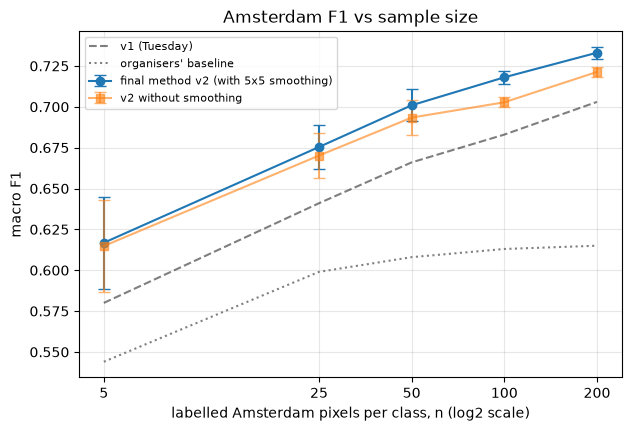

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.log2(table.n_per_class)
ax.errorbar(x, table.f1_mean, yerr=table.f1_std, marker="o", capsize=4, label="final method v2 (with 5x5 smoothing)")
ax.errorbar(x, table.plain_mean, yerr=table.plain_std, marker="s", capsize=4, alpha=.6, label="v2 without smoothing")
ax.plot(x, [0.580, 0.641, 0.666, 0.683, 0.703], "k--", alpha=.5, label="v1 (Tuesday)")
ax.plot(x, [0.544, 0.599, 0.608, 0.613, 0.615], ":", c="grey", label="organisers' baseline")
ax.set_xticks(x, table.n_per_class.astype(str))
ax.set_xlabel("labelled Amsterdam pixels per class, n (log2 scale)"); ax.set_ylabel("macro F1")
ax.set_title("Amsterdam F1 vs sample size"); ax.grid(alpha=.3); ax.legend(fontsize=8)
fig.savefig("f1_vs_log2n_v2.png", dpi=150, bbox_inches="tight"); plt.show()

## Step 5 - Save the Amsterdam models (seed 42) and check they reload

In [8]:
for n in SHOTS:
    f1, model = tv3.adapt_to_amsterdam(data, stage1, n, SEED, METHOD)
    path = f"models/amsterdam_{METHOD}_n{n:03d}_seed{SEED}.joblib"
    joblib.dump(model, path)
    qry = np.setdiff1d(np.arange(len(data["ya"])), model["support_index"])
    again = f1_score(data["ya"][qry], tv3.predict_blend3(joblib.load(path), stage1, data["Xa"][qry]), average="macro")
    assert abs(f1 - again) < 1e-9, "saved model does not reproduce its score"
    print(f"saved {path} (F1 {f1:.4f}, reloaded {again:.4f})")

saved models/amsterdam_blend3_n005_seed42.joblib (F1 0.5525, reloaded 0.5525)
saved models/amsterdam_blend3_n025_seed42.joblib (F1 0.6583, reloaded 0.6583)
saved models/amsterdam_blend3_n050_seed42.joblib (F1 0.6878, reloaded 0.6878)
saved models/amsterdam_blend3_n100_seed42.joblib (F1 0.7058, reloaded 0.7058)
saved models/amsterdam_blend3_n200_seed42.joblib (F1 0.7216, reloaded 0.7216)


## Step 6 - CHECKS
1. v2 must not be worse than v1 (Tuesday's official run) beyond noise.
2. `predict.py` must work end to end with the v2 models: raw file -> clean -> features -> neighbourhood features -> model -> smoothing, one prediction per pixel. We use the dress-rehearsal hidden files as raw input. Those pixels are INSIDE v2's training data, so the scores printed here are NOT a fair test (they will be high): this only checks that the code path works.

In [9]:
V1 = {5: 0.580, 25: 0.641, 50: 0.666, 100: 0.683, 200: 0.703}
for _, r in table.iterrows():
    ok = r.plain_mean >= V1[int(r.n_per_class)] - 2 * r.plain_std
    print(f"n={int(r.n_per_class):<4} v2 without smoothing {r.plain_mean:.4f} vs v1 {V1[int(r.n_per_class)]:.3f} -> {'OK' if ok else 'CHECK'}")
print(f"average v2 final {avg:.4f} | v2 without smoothing {avg_plain:.4f} | v1 0.655 | v1 + 3x3 smoothing 0.671")
if madrid_cv:
    print(f"Madrid: random CV {madrid_cv[0]:.4f} (v1 0.656, optimistic) | spatial CV {madrid_spatial[0]:.4f} (v1 0.616)")

t0 = time.time()
if Path("rehearsal/hidden_amsterdam.parquet").exists():
    o = predict.predict_city("rehearsal/hidden_amsterdam.parquet", "Amsterdam",
                             amsterdam_model_path=f"models/amsterdam_{METHOD}_n025_seed{SEED}.joblib")
    assert len(o) == o[["px_key", "py_key"]].drop_duplicates().shape[0]
    o = predict.predict_city("rehearsal/hidden_madrid.parquet", "Madrid")
    print(f"predict.py end to end OK ({time.time()-t0:.0f}s) (scores above are NOT a fair test, see text)")

n=5    v2 without smoothing 0.6148 vs v1 0.580 -> OK
n=25   v2 without smoothing 0.6702 vs v1 0.641 -> OK
n=50   v2 without smoothing 0.6934 vs v1 0.666 -> OK
n=100  v2 without smoothing 0.7028 vs v1 0.683 -> OK
n=200  v2 without smoothing 0.7213 vs v1 0.703 -> OK
average v2 final 0.6889 | v2 without smoothing 0.6805 | v1 0.655 | v1 + 3x3 smoothing 0.671
Madrid: random CV 0.7328 (v1 0.656, optimistic) | spatial CV 0.6290 (v1 0.616)
temporal haze filter removed 930 photos (0.31% of clean photos)
built 3,477 pixels x 132 features (0 NaN values filled with the city median)
context: 22,515 of our own Amsterdam pixels used as neighbours
Amsterdam: macro F1 on ALL 3,477 pixels = 0.6143
predicted 3,477 pixels; class counts: {1: 865, 2: 915, 3: 1176, 4: 521}
temporal haze filter removed 5,485 photos (0.33% of clean photos)
built 14,532 pixels x 132 features (0 NaN values filled with the city median)
context: 61,731 of our own Madrid pixels used as neighbours
Madrid: macro F1 on ALL 14,532 pixe